# 08 · E4 check: were the training crops reused?

**Question.** In E4 (notebook 07) the step "extra training" (Baseline → R1) explains most of the Baseline → Slakh-FT improvement. Besides more steps and a new learning-rate schedule, the two runs differ in how the training crops are drawn. The original training notebooks (`notebooks/archive/`) create the training DataLoader with `persistent_workers=True` and fetch one batch for a smoke test (cell 10) before the training loop. The workers start at that moment, each with its own copy of the dataset at epoch 0; if they keep that copy, `train_dataset.set_epoch(epoch)` in the loop changes only the copy in the main process, and every epoch uses the crops of epoch 0: the Baseline would have seen the same 14,080 segments (704 tracks × 20 crops) in all 60 epochs. The training loop of R1 and R2 (`src/training_loop.py`) builds a new DataLoader every epoch, so it draws new crops at every epoch. This notebook checks (A) whether the original loader really repeats the crops and (B) whether the models memorized the repeated crops.

**Method.**
- **Part A, the loader.** The Baseline's training dataset is rebuilt as in the archived notebook (manifest `manifests/all_tracks_800.csv`, seed 42, 20 crops per track, 10-s segments). On two tracks, the original loader (persistent workers, smoke-test batch first) and a loader built like the one of `src/training_loop.py` (a new one every epoch) run for three epochs; the start frame of every crop is compared with the crops of epoch 0 and with the crops of the requested epoch.
- **Part B, memorization.** Every checkpoint is evaluated with teacher forcing (same code as Table 1 and notebook 07) on two crops of each of its training tracks: the crop that the original loader repeated (epoch 0, crop 0) and a crop that no run used (epoch 999, crop 0). Only the position of the crop changes; tracks, model and code are the same. The difference is paired by track, with a bootstrap 95% confidence interval over tracks.
  - Baseline (original notebook, 704 tracks) is compared with R1 (new loop, same tracks in the same order). R1 was never trained on either crop, but it starts from the Baseline weights.
  - Slakh-FT is compared with R2 (new loop, same 1229 tracks in the same order). R2 also starts from the Baseline weights; the last cell separates the tracks whose repeated crop is also the Baseline's. The Slakh-FT training notebook is not in the repository: the archived OST notebook (`finetune-of-slakh-baseline-training-8kb.ipynb`) was adapted from it and has the same loader and smoke test, so this part tests whether Slakh-FT behaves like the Baseline.

**Data.** Slakh training tracks: the Baseline's 704 from `manifests/all_tracks_800.csv`, the manifest used for the Baseline (same tracks, order and frame counts as the 704 tracks selected by R1, checked below), and all 1229 tracks of `manifests/all_tracks.csv` for Slakh-FT and R2.

**What it does not show.** How much of the E4 "extra training" step comes from the new crops rather than from the extra steps or the new learning-rate schedule: separating them would need another training run. A fresh crop can partly overlap the repeated crop of the same track; the overlap can only make the measured difference smaller.

**Kaggle settings:** GPU T4, Internet on. **Inputs:** `slakh-tensors-final`, `secunda-slakh-60-epochs` (Baseline), `secunda-finetuned-on-slakh` (Slakh-FT, model) and `secunda-e4-control-runs` (R1 and R2). About 10 minutes on a T4.

In [1]:
# ── Repository bootstrap: make src/ importable on Kaggle and locally ──
# On Kaggle the repository is cloned into /kaggle/working (Internet must be
# enabled in the notebook settings). Locally, set SECUNDA_REPO_DIR to the
# repository root and nothing is cloned.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/DanBracs7/Adaptive-Secunda-Synth.git"
REPO_BRANCH = "revision"  # switch to "main" after merging the revision
REPO_DIR = Path(os.environ.get("SECUNDA_REPO_DIR", "/kaggle/working/Adaptive-Secunda-Synth"))

if not (REPO_DIR / "src").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
        check=True,
    )

sys.path.insert(0, str(REPO_DIR / "src"))

commit = subprocess.run(
    ["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
    capture_output=True,
    text=True,
).stdout.strip()

print("Repository:", REPO_DIR)
print("Commit:", commit or "unknown (not a git checkout)")

Cloning into '/kaggle/working/Adaptive-Secunda-Synth'...


Repository: /kaggle/working/Adaptive-Secunda-Synth
Commit: 8df433c


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset

from audio_dataset import SecundaAudioDataset
from condition_ablation import bootstrap_mean_ci, per_segment_cross_entropy
from frame_codec import NUM_CODEBOOKS, CodebookSerializer
from paths import get_path, running_on_kaggle, source_roots_for_split
from training_loop import filter_rows
from training_utils import load_checkpoint_model, prepare_batch_for_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

RANDOM_SEED = 42            # seed of every training run (archived notebooks and notebook 06)
SAMPLES_PER_TRACK = 20      # crops per track and epoch in every training run
SEGMENT_SECONDS = 10.0
FRAME_RATE = 75
BATCH_SIZE = 24
NUM_WORKERS = 2
REPEATED_EPOCH = 0          # epoch whose crops the original loader keeps (see Question)
FRESH_EPOCH = 999           # used by no run: R1 trained epochs 1-44, R2 epochs 1-25
CROP_INDEX = 0              # Part B evaluates one crop per track: crop 0 of 20
MAX_TRACKS = None           # None = all tracks; e.g. 300 for a shorter run
CODEBOOKS = [f"Q{q}" for q in range(NUM_CODEBOOKS)]

# Manifest used for the Baseline (704 training tracks), and the current one (1229).
BASELINE_MANIFEST = REPO_DIR / "manifests" / "all_tracks_800.csv"
CURRENT_MANIFEST = get_path("manifest")


def checkpoint_path(name):
    path = get_path(name)
    if not path.exists() and running_on_kaggle():
        # An uploaded file can end up in a sub-folder of its dataset.
        matches = sorted(Path("/kaggle/input").rglob(path.name))
        path = matches[0] if matches else path
    return path


CHECKPOINTS = {
    "Baseline": checkpoint_path("ckpt_baseline"),
    "R1": checkpoint_path("ckpt_e4_r1"),
    "Slakh-FT": checkpoint_path("ckpt_slakh_ft"),
    "R2": checkpoint_path("ckpt_e4_r2"),
}
for name, path in CHECKPOINTS.items():
    print(f"{name:9s} exists={path.exists()}  {path}")

OUTPUT_DIR = get_path("output_dir") / "e4_crop_reuse"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Device: Tesla T4
Baseline  exists=True  /kaggle/input/datasets/danielebracoloni/secunda-slakh-60-epochs/secunda_slakh8cb_best_final.pt
R1        exists=True  /kaggle/input/datasets/danielebracoloni/secunda-e4-control-runs/secunda_e4_R1_final_model.pt
Slakh-FT  exists=True  /kaggle/input/models/danielebracoloni/secunda-finetuned-on-slakh/pytorch/default/1/secunda_slakh8cb_finetuneslakh__best.pt
R2        exists=True  /kaggle/input/datasets/danielebracoloni/secunda-e4-control-runs/secunda_e4_R2_final_model.pt


In [3]:
def make_train_dataset(manifest_path):
    # Training dataset as built by the archived Baseline notebook (cell 6)
    # and by notebook 06: same split, stage, seed, crops per track and length.
    return SecundaAudioDataset(
        manifest_path=manifest_path,
        source_roots=source_roots_for_split("train"),
        split="train",
        stage="pretrain",
        segment_seconds=SEGMENT_SECONDS,
        frame_rate=FRAME_RATE,
        fixed_start=False,
        seed=RANDOM_SEED,
        samples_per_track=SAMPLES_PER_TRACK,
    )


def baseline_tracks_only(row):
    # Same selection as notebook 06 for R1: the train split of slakh/train_000-799.
    return int(Path(row["path"]).stem.split("_")[-1]) <= 799


def expected_start(dataset, row_index, crop_index, epoch):
    # Start frame that SecundaAudioDataset._choose_start picks at this epoch.
    previous_epoch = dataset.epoch
    dataset.set_epoch(epoch)
    start = dataset._choose_start(
        row_index=row_index,
        crop_index=crop_index,
        total_frames=int(dataset.rows[row_index]["num_frames"]),
    )
    dataset.set_epoch(previous_epoch)
    return start


baseline_train = make_train_dataset(BASELINE_MANIFEST)
r1_train = filter_rows(make_train_dataset(CURRENT_MANIFEST), baseline_tracks_only)
current_train = make_train_dataset(CURRENT_MANIFEST)

same_rows = (
    [(row["path"], row["num_frames"]) for row in baseline_train.rows]
    == [(row["path"], row["num_frames"]) for row in r1_train.rows]
)
print("Baseline training tracks (all_tracks_800.csv):", len(baseline_train.rows))
print("R1 training tracks (all_tracks.csv, ids <= 799):", len(r1_train.rows))
print("Same tracks, order and frame counts:", same_rows)
print("Slakh-FT / R2 training tracks (all_tracks.csv):", len(current_train.rows))
assert len(baseline_train.rows) == 704 and same_rows
assert len(current_train.rows) == 1229

Baseline training tracks (all_tracks_800.csv): 704
R1 training tracks (all_tracks.csv, ids <= 799): 704
Same tracks, order and frame counts: True
Slakh-FT / R2 training tracks (all_tracks.csv): 1229


### Part A — does the original loader repeat the crops?

Two tracks (40 crops) of the Baseline's training set. The original loader is built as in the archived notebooks (cell 6), and one batch is fetched before the loop as in their smoke test (cell 10); then `set_epoch` is called for epochs 1, 2 and 3, as in their training loop. For each epoch the table counts the crops whose start frame equals the crop of epoch 0 and the crop of the requested epoch.

In [4]:
row_index_of = {row["path"]: index for index, row in enumerate(baseline_train.rows)}
demo = Subset(baseline_train, range(2 * SAMPLES_PER_TRACK))


def collect_starts(loader):
    starts = {}
    for batch in loader:
        for path, crop_index, start in zip(batch["path"], batch["crop_index"].tolist(), batch["start_frame"].tolist()):
            starts[(path, crop_index)] = start
    return starts


def count_matches(starts, epoch):
    matches = {REPEATED_EPOCH: 0, epoch: 0}
    for (path, crop_index), start in starts.items():
        for reference in matches:
            matches[reference] += start == expected_start(baseline_train, row_index_of[path], crop_index, reference)
    return matches[REPEATED_EPOCH], matches[epoch]


part_a = []

# Original training notebooks: one loader with persistent workers; the
# smoke test fetches a batch before the training loop (dataset at epoch 0).
baseline_train.set_epoch(0)
original_loader = DataLoader(demo, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                             pin_memory=True, persistent_workers=True)
smoke_batch = next(iter(original_loader))
for epoch in (1, 2, 3):
    baseline_train.set_epoch(epoch)
    part_a.append(("original notebooks", epoch, len(demo), *count_matches(collect_starts(original_loader), epoch)))
del original_loader, smoke_batch

# src/training_loop.py: a new loader, without persistent workers, every epoch.
for epoch in (1, 2, 3):
    baseline_train.set_epoch(epoch)
    loader = DataLoader(demo, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    part_a.append(("src/training_loop.py", epoch, len(demo), *count_matches(collect_starts(loader), epoch)))
baseline_train.set_epoch(0)

part_a = pd.DataFrame(part_a, columns=["loader", "set_epoch", "crops", "same crop as epoch 0", "same crop as set_epoch"])
part_a.to_csv(OUTPUT_DIR / "part_a_loader.csv", index=False)
print(part_a.to_string(index=False))

new_loop = part_a[part_a["loader"] == "src/training_loop.py"]
assert (new_loop["same crop as set_epoch"] == new_loop["crops"]).all(), "expected_start does not match the dataset"


              loader  set_epoch  crops  same crop as epoch 0  same crop as set_epoch
  original notebooks          1     40                    40                       0
  original notebooks          2     40                    40                       0
  original notebooks          3     40                    40                       0
src/training_loop.py          1     40                     0                      40
src/training_loop.py          2     40                     0                      40
src/training_loop.py          3     40                     0                      40


### Part B — did the models memorize the repeated crops?

For every checkpoint and every training track: the cross-entropy on the crop that the original loader repeated (epoch 0) and on a fresh crop (epoch 999), crop 0 in both. Unweighted mean over the eight codebooks, as in E4.

In [5]:
serializer = CodebookSerializer()

GROUPS = {
    # The Baseline's 704 tracks, in the order of its manifest (same as R1's).
    "704 tracks": {"manifest": BASELINE_MANIFEST, "checkpoints": ["Baseline", "R1"]},
    # All 1229 tracks, in the order of the current manifest (Slakh-FT and R2).
    "1229 tracks": {"manifest": CURRENT_MANIFEST, "checkpoints": ["Slakh-FT", "R2"]},
}


def crop_set(manifest_path, epoch):
    # One crop per track (crop CROP_INDEX) as chosen at `epoch`.
    dataset = make_train_dataset(manifest_path)
    dataset.set_epoch(epoch)
    indices = [row_index * SAMPLES_PER_TRACK + CROP_INDEX for row_index in range(len(dataset.rows))]
    return Subset(dataset, indices[:MAX_TRACKS])


@torch.no_grad()
def evaluate(model, crops):
    # Cross-entropy of every segment and codebook [N, Q], with track ids and start frames.
    loader = DataLoader(crops, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    segment_ce, track_ids, start_frames = [], [], []
    for batch in loader:
        prepared = prepare_batch_for_model(batch, serializer, device)
        logits = model(
            input_codes=prepared["input_codes"],
            input_tension=prepared["input_tension"],
            input_combat=prepared["input_combat"],
            target_tension=prepared["target_tension"],
            target_combat=prepared["target_combat"],
        )
        mean_ce, _ = per_segment_cross_entropy(logits, prepared["target_codes"])
        segment_ce.append(mean_ce.cpu().numpy())
        track_ids += list(batch["track_id"])
        start_frames += batch["start_frame"].tolist()
    return np.concatenate(segment_ce), track_ids, start_frames


records = []
started = time.time()
for group, spec in GROUPS.items():
    crops = {"repeated": crop_set(spec["manifest"], REPEATED_EPOCH), "fresh": crop_set(spec["manifest"], FRESH_EPOCH)}
    for name in spec["checkpoints"]:
        model, _ = load_checkpoint_model(CHECKPOINTS[name], device)
        for kind, subset in crops.items():
            segment_ce, track_ids, start_frames = evaluate(model, subset)
            records.append(pd.DataFrame(segment_ce, columns=CODEBOOKS).assign(
                checkpoint=name, group=group, crops=kind, track_id=track_ids, start_frame=start_frames))
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print(f"{name:9s} evaluated on {len(crops['repeated'])} tracks ({(time.time() - started) / 60:.1f} min)")

segments = pd.concat(records, ignore_index=True)
segments["unweighted"] = segments[CODEBOOKS].mean(axis=1)
segments.to_csv(OUTPUT_DIR / "segment_cross_entropy.csv", index=False)

# The evaluated crops must be the ones the training loaders pick for crop
# CROP_INDEX at REPEATED_EPOCH and FRESH_EPOCH.
for group, spec in GROUPS.items():
    reference = make_train_dataset(spec["manifest"])
    for kind, epoch in (("repeated", REPEATED_EPOCH), ("fresh", FRESH_EPOCH)):
        expected = [expected_start(reference, row_index, CROP_INDEX, epoch)
                    for row_index in range(len(reference.rows))][:MAX_TRACKS]
        evaluated = segments[(segments["group"] == group) & (segments["crops"] == kind)]
        for name, starts in evaluated.groupby("checkpoint")["start_frame"]:
            assert starts.tolist() == expected, (group, kind, name)
print(f"PASS: every evaluated crop is crop {CROP_INDEX} of epoch {REPEATED_EPOCH} or {FRESH_EPOCH}.")

/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Baseline  evaluated on 704 tracks (1.2 min)


/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


R1        evaluated on 704 tracks (2.2 min)


/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Slakh-FT  evaluated on 1229 tracks (4.0 min)


/kaggle/working/Adaptive-Secunda-Synth/src/model.py:107: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


R2        evaluated on 1229 tracks (5.7 min)
PASS: every evaluated crop is crop 0 of epoch 0 or 999.


checkpoint  tracks ce_repeated ce_fresh   delta  ci_low ci_high lower_on_repeated mean_overlap
  Baseline     704      4.6955   5.0484 -0.3529 -0.4101 -0.2958               81%           4%
        R1     704      4.6921   4.8021 -0.1100 -0.1644 -0.0567               63%           4%
  Slakh-FT    1229      4.7883   4.8904 -0.1021 -0.1397 -0.0636               66%           5%
        R2    1229      4.8604   4.8685 -0.0081 -0.0450 +0.0298               51%           5%

checkpoint     Q0     Q1     Q2     Q3     Q4     Q5     Q6     Q7
  Baseline -0.582 -0.566 -0.489 -0.348 -0.261 -0.220 -0.192 -0.166
        R1 -0.142 -0.141 -0.148 -0.118 -0.095 -0.089 -0.079 -0.070
  Slakh-FT -0.084 -0.094 -0.146 -0.135 -0.126 -0.097 -0.073 -0.064
        R2 -0.011 -0.006 -0.007 -0.013 -0.009 -0.006 -0.004 -0.009


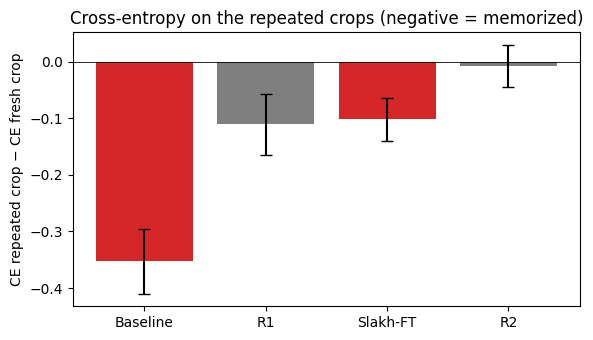

In [6]:
segment_frames = int(round(SEGMENT_SECONDS * FRAME_RATE))
summary = []
for name in CHECKPOINTS:
    own = segments[segments["checkpoint"] == name]
    repeated = own[own["crops"] == "repeated"].set_index("track_id")
    fresh = own[own["crops"] == "fresh"].set_index("track_id").loc[repeated.index]
    # Negative: lower cross-entropy on the repeated crop than on the fresh one.
    difference = repeated["unweighted"] - fresh["unweighted"]
    delta, ci_low, ci_high = bootstrap_mean_ci(difference.to_numpy())
    overlap = np.clip(segment_frames - (repeated["start_frame"] - fresh["start_frame"]).abs(), 0, None) / segment_frames
    summary.append({
        "checkpoint": name,
        "tracks": len(difference),
        "ce_repeated": repeated["unweighted"].mean(),
        "ce_fresh": fresh["unweighted"].mean(),
        "delta": delta,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "lower_on_repeated": (difference < 0).mean(),
        "mean_overlap": overlap.mean(),
        **{f"delta_{q}": (repeated[q] - fresh[q]).mean() for q in CODEBOOKS},
    })
summary = pd.DataFrame(summary)
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)

signed = lambda value: f"{value:+.4f}"
with pd.option_context("display.width", 160):
    print(summary[["checkpoint", "tracks", "ce_repeated", "ce_fresh", "delta", "ci_low", "ci_high",
                   "lower_on_repeated", "mean_overlap"]].to_string(index=False, formatters={
        "ce_repeated": "{:.4f}".format, "ce_fresh": "{:.4f}".format, "delta": signed, "ci_low": signed,
        "ci_high": signed, "lower_on_repeated": "{:.0%}".format, "mean_overlap": "{:.0%}".format}))
    print()
    print(summary[["checkpoint"] + [f"delta_{q}" for q in CODEBOOKS]].rename(
        columns={f"delta_{q}": q for q in CODEBOOKS}).to_string(index=False, float_format=lambda value: f"{value:+.3f}"))

figure, axis = plt.subplots(figsize=(6, 3.5))
errors = np.array([summary["delta"] - summary["ci_low"], summary["ci_high"] - summary["delta"]])
axis.bar(summary["checkpoint"], summary["delta"], yerr=errors, capsize=4,
         color=["tab:red", "tab:gray", "tab:red", "tab:gray"])
axis.axhline(0, color="black", linewidth=0.6)
axis.set_ylabel("CE repeated crop − CE fresh crop")
axis.set_title("Cross-entropy on the repeated crops (negative = memorized)")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "crop_reuse.png", dpi=150)
plt.show()

### Tracks whose repeated crop is also the Baseline's

Slakh-FT and R2 start from the Baseline weights. The tracks that have the same row index in both manifests have the same repeated crop as in the Baseline, so on them part of the difference can come from the Baseline. The two groups are measured separately.

In [7]:
baseline_crop = {row["path"]: expected_start(baseline_train, row_index, CROP_INDEX, REPEATED_EPOCH)
                 for row_index, row in enumerate(baseline_train.rows)}
shares_baseline_crop = {
    row["track_id"]: baseline_crop.get(row["path"]) == expected_start(current_train, row_index, CROP_INDEX, REPEATED_EPOCH)
    for row_index, row in enumerate(current_train.rows)
}

split = []
for name in ("Slakh-FT", "R2"):
    own = segments[segments["checkpoint"] == name]
    repeated = own[own["crops"] == "repeated"].set_index("track_id")
    fresh = own[own["crops"] == "fresh"].set_index("track_id").loc[repeated.index]
    difference = repeated["unweighted"] - fresh["unweighted"]
    shared = np.array([shares_baseline_crop[track_id] for track_id in difference.index])
    for label, mask in (("shared with the Baseline", shared), ("not shared", ~shared)):
        delta, ci_low, ci_high = bootstrap_mean_ci(difference[mask].to_numpy())
        split.append({"checkpoint": name, "repeated crop": label, "tracks": int(mask.sum()),
                      "delta": delta, "ci_low": ci_low, "ci_high": ci_high})
split = pd.DataFrame(split)
split.to_csv(OUTPUT_DIR / "split_by_baseline_crop.csv", index=False)
print(split.to_string(index=False, formatters={"delta": signed, "ci_low": signed, "ci_high": signed}))

checkpoint            repeated crop  tracks   delta  ci_low ci_high
  Slakh-FT shared with the Baseline      92 -0.3203 -0.4901 -0.1657
  Slakh-FT               not shared    1137 -0.0845 -0.1232 -0.0454
        R2 shared with the Baseline      92 -0.1978 -0.3664 -0.0490
        R2               not shared    1137 +0.0073 -0.0308 +0.0464


### How to read the result

- **Part A.** If every crop of the original loader equals the crop of epoch 0 at every `set_epoch`, the original notebooks trained on the same crops at every epoch; the loader of `src/training_loop.py` must instead follow `set_epoch`.
- **Part B.** `delta` is the cross-entropy on the repeated crop minus the cross-entropy on the fresh crop, averaged over tracks; negative means lower on the repeated crop. Both crops are random positions in the same track, so a model never trained on the repeated crops, directly or through its starting weights, should have `delta` close to 0.
  - R2 is the control for Slakh-FT: same tracks in the same order, new crops at every epoch. Through the Baseline weights it can only inherit something on the tracks whose repeated crop is shared with the Baseline (last cell).
  - R1 is not a clean control: all its repeated crops are the Baseline's, and it starts from the Baseline weights. Its `delta` shows how much of the Baseline's memorization is left after 44 epochs on new crops.
- For comparison, the training losses already logged (Baseline loss weights, dropout on): the Baseline's last epoch had 4.592 on its training crops (notebook 00); the first epoch of R1, which starts from the Baseline weights on the same tracks with new crops, had 4.862 (`results/e4/R1/history.json`).

### Results of this run

**Part A.** At every `set_epoch` (1, 2 and 3) the original loader returns the crop of epoch 0 for all 40 crops, while the loader of `src/training_loop.py` returns the crop of the requested epoch for all 40. The original training notebooks therefore trained on the same 20 crops per track, chosen at epoch 0, in every epoch; only their order changed.

**Part B** (unweighted cross-entropy, crop 0 of every training track; Δ = repeated − fresh, 95% bootstrap CI over tracks):

| Checkpoint | Tracks | CE repeated | CE fresh | Δ | 95% CI | Tracks lower on repeated |
|---|---|---|---|---|---|---|
| Baseline | 704 | 4.696 | 5.048 | −0.353 | [−0.410, −0.296] | 81% |
| R1 | 704 | 4.692 | 4.802 | −0.110 | [−0.164, −0.057] | 63% |
| Slakh-FT | 1229 | 4.788 | 4.890 | −0.102 | [−0.140, −0.064] | 66% |
| R2 | 1229 | 4.860 | 4.869 | −0.008 | [−0.045, +0.030] | 51% |

Split by whether the repeated crop is also the Baseline's:

| Checkpoint | Shared with the Baseline (92 tracks) | Not shared (1137 tracks) |
|---|---|---|
| Slakh-FT | −0.320 [−0.490, −0.166] | −0.085 [−0.123, −0.045] |
| R2 | −0.198 [−0.366, −0.049] | +0.007 [−0.031, +0.046] |

**Interpretation.**
- The Baseline memorized its repeated crops: its cross-entropy is 0.35 lower on them than on new crops of the same tracks, on 81% of the tracks, most on Q0–Q2 (−0.49 to −0.58). For comparison, the whole Baseline → Slakh-FT improvement on the test set is 0.295.
- The position of a crop alone makes no difference: on the 1137 tracks whose repeated crop the Baseline never saw, R2 has Δ = +0.007.
- On the same 1137 tracks Slakh-FT has Δ = −0.085: it memorized its own repeated crops, so its training notebook reused the crops in the same way.
- The memorization passes through the starting weights and fades with training on new crops: on the 92 tracks whose repeated crop is the Baseline's (91 with the same row index in both manifests, one by chance), R2 keeps −0.198 after 25 epochs; R1, on all 704, keeps −0.110 after 44 epochs.
- Consequences for E4 (notebook 07). The step "extra training" (Baseline → R1) also replaces 14,080 fixed segments with new crops at every epoch, so it cannot be attributed to the extra steps or the new learning-rate schedule alone. The step "new loss weights" (R2 → Slakh-FT) compares a run with new crops at every epoch with a run that reused its crops, so its cost (+0.034) also contains that difference. The step "new data" (R1 → R2) compares two runs of the new loop and is not affected. Table 1, E1, E2 and E3 evaluate the checkpoints as they are and are not affected.
- OST-FT was trained with the same notebook (`finetune-of-slakh-baseline-training-8kb.ipynb`), so it also reused its crops (from the code; not measured here). It is not part of E4.